## Implementasi

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

np.random.seed(42)
PROCESSED_DIR = "../content/data/processed"
CLASS_NAMES = ["Low", "Medium", "Critical"]

In [ ]:
data = np.load(os.path.join(PROCESSED_DIR, "classical_features.npz"))
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]

FEATURE_SET = "color"
if FEATURE_SET == "color":
    X_train, X_val = X_train[:, :96], X_val[:, :96]

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print("Distribusi train:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Distribusi val  :", dict(zip(*np.unique(y_val, return_counts=True))))

X_train: (465, 96) | X_val: (133, 96)
Distribusi train: {np.int64(0): np.int64(27), np.int64(1): np.int64(176), np.int64(2): np.int64(262)}
Distribusi val  : {np.int64(0): np.int64(9), np.int64(1): np.int64(47), np.int64(2): np.int64(77)}


In [10]:
baseline = LogisticRegression(
    penalty="l2", C=1.0, solver="lbfgs",
    max_iter=1000, class_weight="balanced", random_state=42
)

t0 = time.time()
baseline.fit(X_train, y_train)
train_time = time.time() - t0
print(f"Waktu training: {train_time:.2f} s | iterasi: {baseline.n_iter_}")

Waktu training: 0.10 s | iterasi: [143]


## Hasil Awal (Validation Set)

In [11]:
t0 = time.time()
y_pred_val = baseline.predict(X_val)
infer_time = time.time() - t0

y_pred_train = baseline.predict(X_train)
acc_tr = accuracy_score(y_train, y_pred_train)
acc = accuracy_score(y_val, y_pred_val)
p, r, f1, _ = precision_recall_fscore_support(y_val, y_pred_val, average="macro", zero_division=0)

print(f"Train accuracy       : {acc_tr:.4f}")
print(f"Val accuracy         : {acc:.4f}")
print(f"Val macro precision  : {p:.4f}")
print(f"Val macro recall     : {r:.4f}")
print(f"Val macro F1         : {f1:.4f}")
print(f"Inference time (val) : {infer_time:.4f} s")
print()
print(classification_report(y_val, y_pred_val, target_names=CLASS_NAMES, zero_division=0))

Train accuracy       : 0.6602
Val accuracy         : 0.4436
Val macro precision  : 0.3834
Val macro recall     : 0.3844
Val macro F1         : 0.3637
Inference time (val) : 0.0009 s

              precision    recall  f1-score   support

         Low       0.08      0.22      0.12         9
      Medium       0.40      0.49      0.44        47
    Critical       0.67      0.44      0.53        77

    accuracy                           0.44       133
   macro avg       0.38      0.38      0.36       133
weighted avg       0.53      0.44      0.47       133



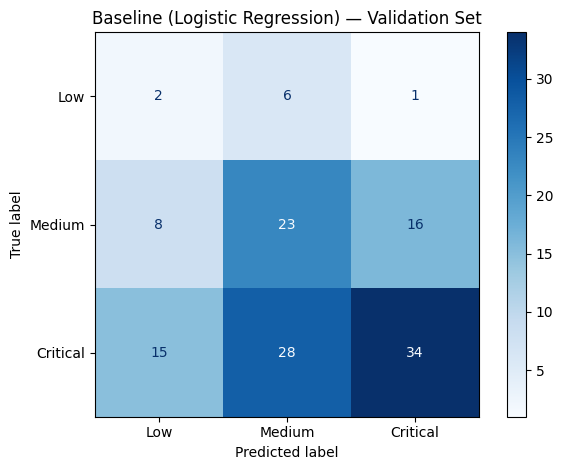

In [12]:
cm = confusion_matrix(y_val, y_pred_val, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title("Baseline (Logistic Regression) — Validation Set")
plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/baseline_confusion_matrix_val.png", dpi=150)
plt.show()

In [13]:
# Simpan skor untuk dibandingkan dengan model advanced
os.makedirs(PROCESSED_DIR, exist_ok=True)
results = {
    "model": "Logistic Regression", "feature_set": FEATURE_SET,
    "params": {"C": 1.0, "penalty": "l2", "solver": "lbfgs", "max_iter": 1000,
               "class_weight": "balanced", "random_state": 42},
    "val_accuracy": acc, "val_macro_precision": p, "val_macro_recall": r,
    "val_macro_f1": f1, "train_accuracy": acc_tr,
    "train_time_s": train_time, "inference_time_s": infer_time,
}
with open(os.path.join(PROCESSED_DIR, "baseline_val_results.json"), "w") as f:
    json.dump(results, f, indent=2)
results

{'model': 'Logistic Regression',
 'feature_set': 'color',
 'params': {'C': 1.0,
  'penalty': 'l2',
  'solver': 'lbfgs',
  'max_iter': 1000,
  'class_weight': 'balanced',
  'random_state': 42},
 'val_accuracy': 0.44360902255639095,
 'val_macro_precision': 0.383391812865497,
 'val_macro_recall': 0.38438078863610775,
 'val_macro_f1': 0.36373491704374056,
 'train_accuracy': 0.6602150537634408,
 'train_time_s': 0.09613823890686035,
 'inference_time_s': 0.0009238719940185547}